# 11 - Mushroom final test

**Question:** does our frozen alarm work on unseen rows?

Final evaluation: Tomislav Novosel, with Codex assistance. Reviewed by the team on 22 October 2026.

We selected the original Extra Trees fit from development evidence. Its lower cutoff came from calibration, not the final test. We froze that cutoff and the default 0.5 comparison first. The evaluator then used the 1,000 reserved rows once.

This notebook reads the saved results. It does not fit a model or run the final test again.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import sys
ROOT = Path.cwd() if (Path.cwd() / "release_decision.json").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.release_integrity import verify_release, digest
release = verify_release(required=True)
results = json.loads((ROOT / "reports/final_test_results.json").read_text())
assert results["status"] == "complete"
assert results["decision_sha256"] == digest(ROOT / "release_decision.json", text=True)
print("Frozen before testing:", release["utc"])
print("Final evaluation completed:", results["utc"])
print("Operator:", results["operator"], "- Codex assistance")


Frozen before testing: 2026-10-13T19:05:46.188770+00:00
Final evaluation completed: 2026-10-13T19:06:07.975394+00:00
Operator: Tomislav Novosel - Codex assistance


## Read the alarm results

A caught poison label is a correct alarm. An edible label flagged is a false alarm. A missed poison label is a dangerous error. Neither rule establishes real food safety.

In [2]:
rows=[]
for name, key in [("Lower cutoff", "mushrooms"), ("Default", "mushrooms_default")]:
    m=results[key]
    rows.append({"rule":name,"cutoff":m["threshold"],"poison caught":m["tp"],"poison missed":m["fn"],
                 "edible false alarms":m["fp"],"edible not flagged":m["tn"],
                 "poison recall":m["poison_recall"],"accuracy":m["accuracy"]})
table=pd.DataFrame(rows).set_index("rule")
print("Reserved rows:", results["mushroom_test_rows"])
display(table.round(4))


Reserved rows: 1000


,cutoff,poison caught,poison missed,edible false alarms,edible not flagged,poison recall,accuracy
rule,,,,,,,
Lower cutoff,0.0398,373,5,598,24,0.9868,0.397
Default,0.5000,236,142,73,549,0.6243,0.785


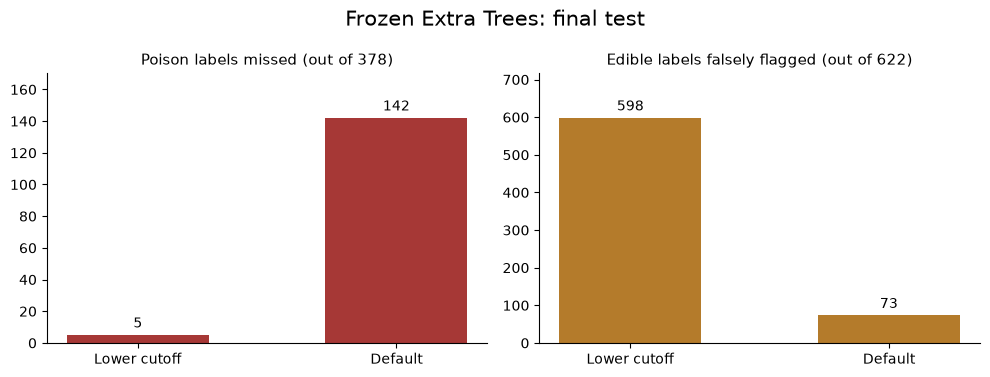

In [3]:
fig, axes=plt.subplots(1,2,figsize=(10,3.8))
for ax,field,color,title in [(axes[0],"poison missed","#a63836","Poison labels missed (out of 378)"),
                            (axes[1],"edible false alarms","#b47b2b","Edible labels falsely flagged (out of 622)")]:
    values=table[field].to_numpy()
    bars=ax.bar(table.index,values,color=color,width=.55)
    ax.bar_label(bars,padding=3)
    ax.set_title(title,fontsize=11)
    ax.set_ylim(0,max(values)*1.2)
    ax.spines[["top","right"]].set_visible(False)
fig.suptitle("Frozen Extra Trees: final test",fontsize=15)
fig.tight_layout()
fig.savefig(ROOT / "reports/final_mushroom_tradeoff.png",dpi=160,bbox_inches="tight")
plt.show()


## What this tells us

- The lower rule caught 373/378 poisonous labels (98.7%). It still missed 5.
- It falsely flagged 598/622 edible labels (96.1%). It raised an alarm for almost everything.
- The default rule caught 236/378, missed 142 and raised 73 false alarms. Its 78.5% accuracy hides the poor poison recall.
- A lower cutoff traded fewer misses for many more false alarms. This supports our development finding; it does not produce a useful zero-miss classifier.

We kept the frozen fit and cutoff. We did not remove difficult rows or tune on these results. The app displays both rules so the tradeoff is visible. Do not use it to decide what to eat.